Import libraries and configure folders

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path
from IPython.display import display

from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import (
    KFold, cross_validate, cross_val_predict, learning_curve
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

project_dir = Path(
    r"C:\Users\U S E R\Desktop\ML Assigment\project"
)

models_dir = project_dir / "models"
output_dir = project_dir / "output" / "linear_regression"
results_dir = (
    project_dir / "data" / "processed" / "model_comparisons"
)

for folder in [models_dir, output_dir, results_dir]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

def save_plot(filename):
    plt.savefig(
        output_dir / filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )
    plt.show()
    plt.close()

print("Folders configured successfully.")

Folders configured successfully.


Load your final processed training and testing datasets

In [19]:
train_path = (
    project_dir / "data" / "processed" /
    "math_train_processed.csv"
)

test_path = (
    project_dir / "data" / "processed" /
    "math_test_processed.csv"
)

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

X_train = train_df.drop(columns=["G3"])
y_train = train_df["G3"]

X_test = test_df.drop(columns=["G3"])
y_test = test_df["G3"]

assert X_train.columns.equals(X_test.columns)
assert X_train.notna().all().all()
assert X_test.notna().all().all()

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

display(X_train.head())

Training: (316, 58)
Testing: (79, 58)


,num__age,num__Medu,num__Fedu,num__traveltime,num__studytime,num__failures,num__famrel,num__freetime,num__goout,num__Dalc,...,cat__activities_no,cat__activities_yes,cat__nursery_no,cat__nursery_yes,cat__higher_no,cat__higher_yes,cat__internet_no,cat__internet_yes,cat__romantic_no,cat__romantic_yes
0,-0.5,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
1,-0.5,-0.5,0.0,1.0,-1.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
2,-0.5,-1.0,0.0,0.0,0.0,3.0,0.0,0.0,1.0,0.0,...,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
3,-0.5,0.5,0.0,0.0,1.0,0.0,-1.0,1.0,0.5,1.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
4,-0.5,-0.5,-2.0,1.0,-1.0,0.0,-1.0,0.0,-0.5,0.0,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0


Define the three experiments

In [21]:
g1_cols = [
    col for col in X_train.columns
    if col == "num__G1"
]

g2_cols = [
    col for col in X_train.columns
    if col == "num__G2"
]

assert len(g1_cols) == 1, "G1 column not found"
assert len(g2_cols) == 1, "G2 column not found"

experiments = {
    "LR-1 All Features": X_train.columns.tolist(),

    "LR-2 Without G1": [
        col for col in X_train.columns
        if col not in g1_cols
    ],

    "LR-3 Without G1 G2": [
        col for col in X_train.columns
        if col not in g1_cols + g2_cols
    ]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "R2": "r2"
}

for name, features in experiments.items():
    print(name, ":", len(features), "features")

LR-1 All Features : 58 features
LR-2 Without G1 : 57 features
LR-3 Without G1 G2 : 56 features


Create reusable evaluation functions

In [22]:
GRADE_LABELS = ["Low", "Medium", "High"]

def grade_category(values):
    values = np.asarray(values)

    return np.where(
        values < 10,
        "Low",
        np.where(values < 15, "Medium", "High")
    )


def evaluate_predictions(y_true, y_pred):

    actual = np.asarray(y_true)
    predicted = np.asarray(y_pred)

    rounded = np.clip(
        np.rint(predicted), 0, 20
    ).astype(int)

    actual_cat = grade_category(actual)
    predicted_cat = grade_category(predicted)

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mean_squared_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted),

        "Exact Accuracy (%)": (
            np.mean(rounded == actual) * 100
        ),

        "Within 1 Grade (%)": (
            np.mean(np.abs(actual - predicted) <= 1) * 100
        ),

        "Within 2 Grades (%)": (
            np.mean(np.abs(actual - predicted) <= 2) * 100
        ),

        "Category Accuracy (%)": (
            accuracy_score(actual_cat, predicted_cat) * 100
        ),

        "Precision": precision_score(
            actual_cat, predicted_cat,
            average="weighted",
            zero_division=0
        ),

        "Recall": recall_score(
            actual_cat, predicted_cat,
            average="weighted",
            zero_division=0
        ),

        "F1 Score": f1_score(
            actual_cat, predicted_cat,
            average="weighted",
            zero_division=0
        )
    }

Train all experiments and calculate all metrics


Training: LR-1 All Features

Training: LR-2 Without G1

Training: LR-3 Without G1 G2


,Experiment,Features,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train R2,Validation R2,RMSE Gap,Exact Accuracy (%),Within 1 Grade (%),Within 2 Grades (%),Category Accuracy (%),Precision,Recall,F1 Score
0,LR-1 All Features,58,1.1250,1.3724,1.5492,1.8829,0.8855,0.8239,0.3337,30.3797,51.8987,78.7975,80.3797,0.8232,0.8038,0.8026
1,LR-2 Without G1,57,1.1361,1.3795,1.5845,1.9211,0.8802,0.8168,0.3366,31.3291,50.6329,77.8481,80.6962,0.8222,0.8070,0.8063
2,LR-3 Without G1 G2,56,2.8546,3.4763,3.6714,4.4615,0.3554,-0.0308,0.7902,11.7089,23.1013,37.3418,51.5823,0.4810,0.5158,0.4865


,Experiment,Fold,Train RMSE,Validation RMSE,Train MAE,Validation MAE,Train R2,Validation R2
0,LR-1 All Features,1,1.6170,1.5748,1.1730,1.2191,0.8830,0.8273
1,LR-1 All Features,2,1.4409,2.3401,1.0116,1.6294,0.8892,0.8181
2,LR-1 All Features,3,1.5998,1.6627,1.1665,1.2443,0.8874,0.8032
3,LR-1 All Features,4,1.6205,1.6350,1.1998,1.1725,0.8753,0.8657
4,LR-1 All Features,5,1.4678,2.2020,1.0743,1.5965,0.8925,0.8051
5,LR-2 Without G1,1,1.6640,1.5582,1.1878,1.1252,0.8761,0.8309
6,LR-2 Without G1,2,1.4666,2.4291,1.0166,1.6686,0.8852,0.8040
7,LR-2 Without G1,3,1.6319,1.7287,1.1790,1.2747,0.8829,0.7872
8,LR-2 Without G1,4,1.6581,1.6491,1.2155,1.2369,0.8695,0.8634
9,LR-2 Without G1,5,1.5020,2.2403,1.0817,1.5922,0.8874,0.7983


Visualize training vs validation metrics

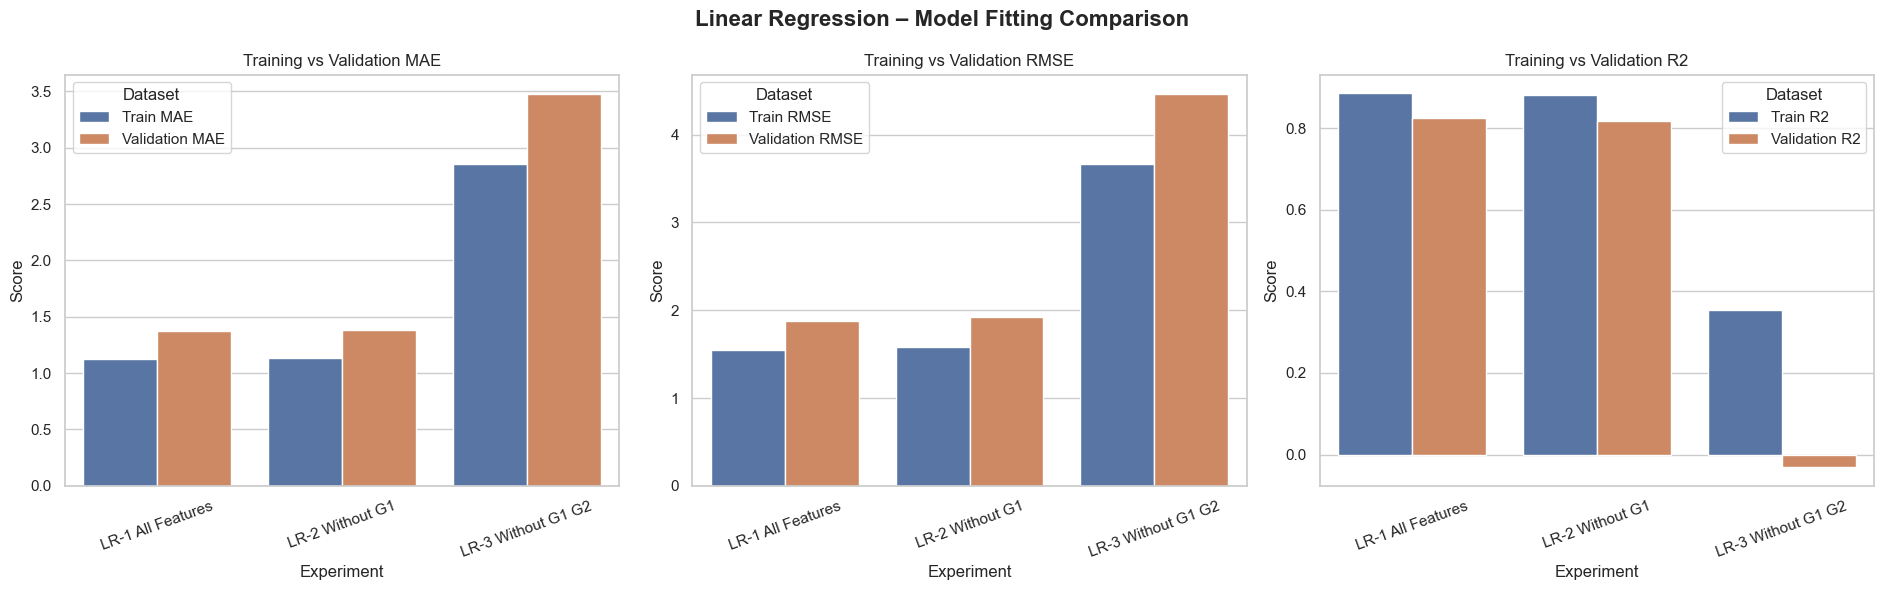

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):

    plot_data = lr_results.melt(
        id_vars="Experiment",
        value_vars=[
            f"Train {metric}",
            f"Validation {metric}"
        ],
        var_name="Dataset",
        value_name="Score"
    )

    sns.barplot(
        data=plot_data,
        x="Experiment",
        y="Score",
        hue="Dataset",
        ax=ax
    )

    ax.set_title(f"Training vs Validation {metric}")
    ax.tick_params(axis="x", rotation=20)

plt.suptitle(
    "Linear Regression – Model Fitting Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
save_plot("01_LR_Training_Validation.png")

Accuracy comparison across all three experiments

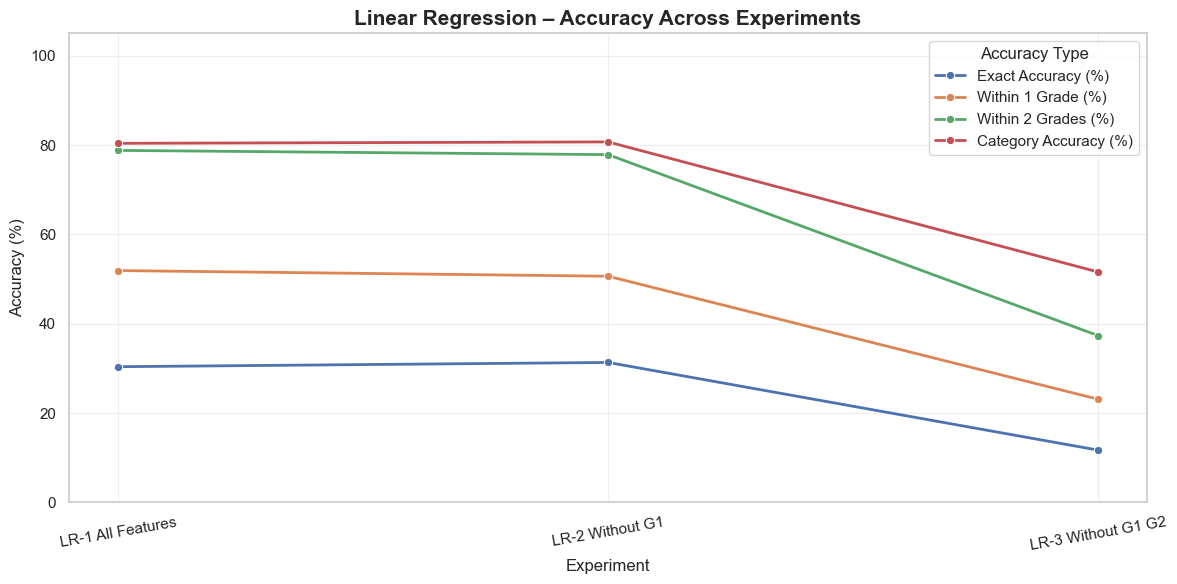

In [25]:
accuracy_cols = [
    "Exact Accuracy (%)",
    "Within 1 Grade (%)",
    "Within 2 Grades (%)",
    "Category Accuracy (%)"
]

accuracy_long = lr_results.melt(
    id_vars="Experiment",
    value_vars=accuracy_cols,
    var_name="Accuracy Type",
    value_name="Accuracy (%)"
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=accuracy_long,
    x="Experiment",
    y="Accuracy (%)",
    hue="Accuracy Type",
    marker="o",
    linewidth=2
)

plt.title(
    "Linear Regression – Accuracy Across Experiments",
    fontsize=15,
    fontweight="bold"
)

plt.ylim(0, 105)
plt.xlabel("Experiment")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=10)
plt.grid(alpha=0.3)

plt.tight_layout()
save_plot("02_LR_Accuracy_Flow.png")

Precision, Recall and F1 comparison

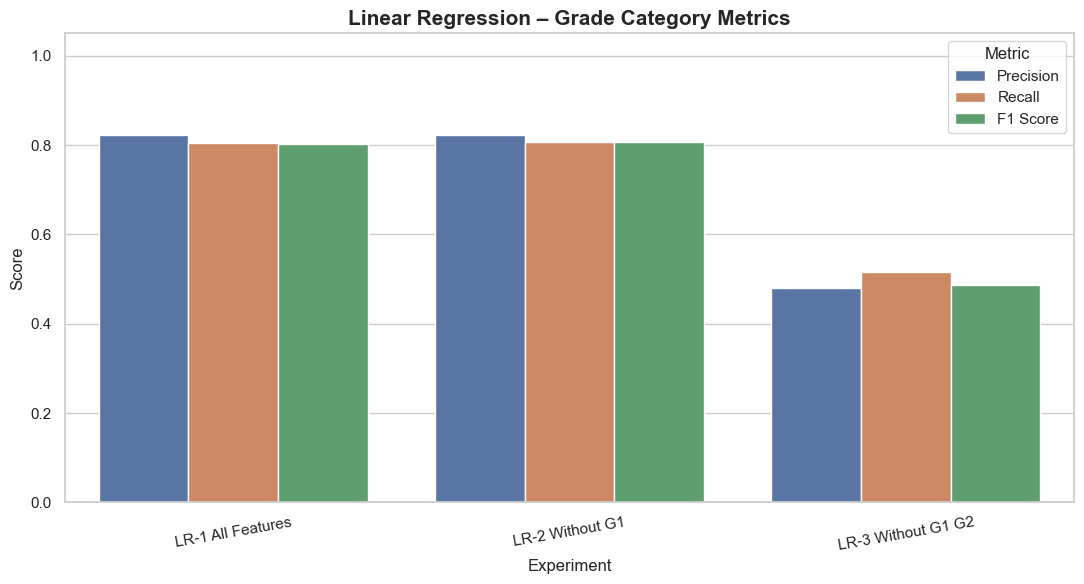

In [26]:
classification_long = lr_results.melt(
    id_vars="Experiment",
    value_vars=["Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=classification_long,
    x="Experiment",
    y="Score",
    hue="Metric"
)

plt.title(
    "Linear Regression – Grade Category Metrics",
    fontsize=15,
    fontweight="bold"
)

plt.ylim(0, 1.05)
plt.xticks(rotation=10)

plt.tight_layout()
save_plot("03_LR_Classification_Metrics.png")

Confusion matrix for every experiment

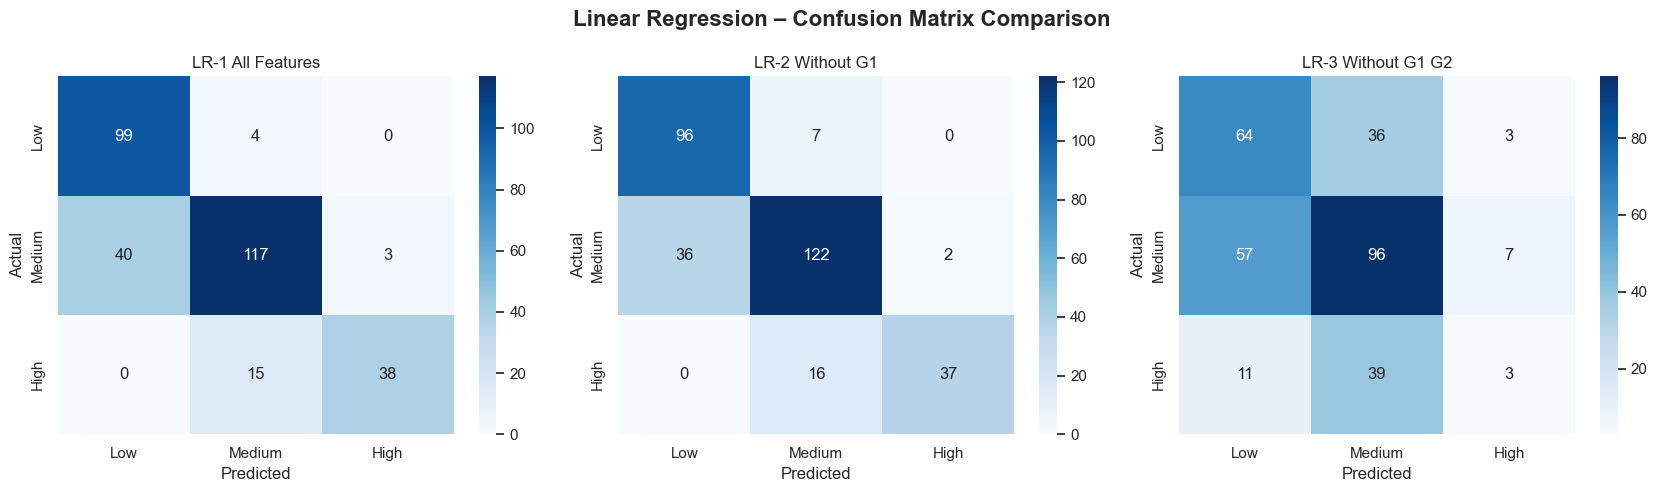

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

actual_cat = grade_category(y_train)

for ax, (name, y_pred) in zip(
    axes, prediction_results.items()
):

    predicted_cat = grade_category(y_pred)

    cm = confusion_matrix(
        actual_cat,
        predicted_cat,
        labels=GRADE_LABELS
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=GRADE_LABELS,
        yticklabels=GRADE_LABELS,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle(
    "Linear Regression – Confusion Matrix Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
save_plot("04_LR_All_Confusion_Matrices.png")

Visualize RMSE across cross-validation folds

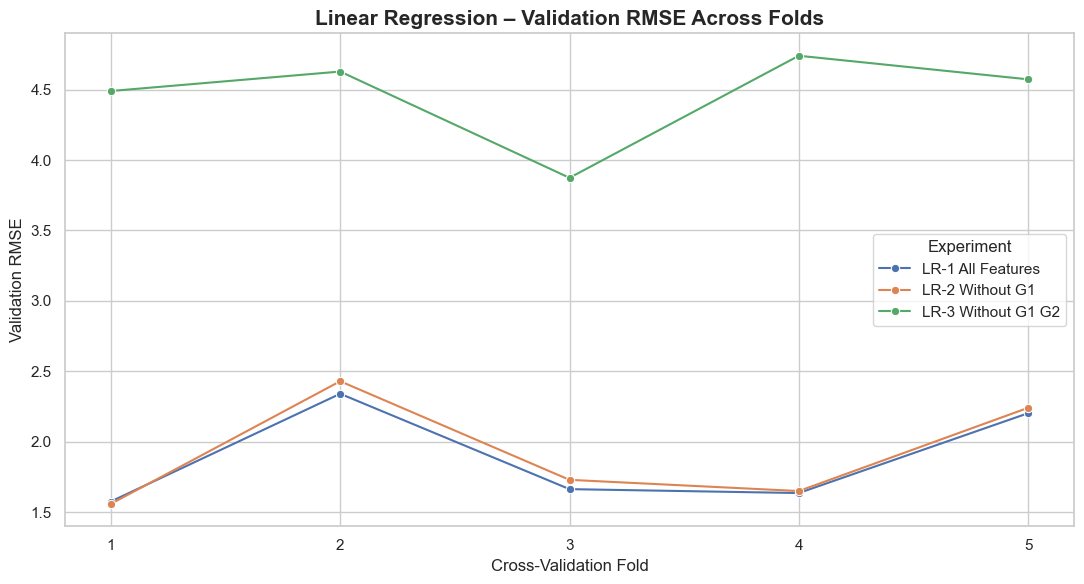

In [30]:
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=lr_fold_results,
    x="Fold",
    y="Validation RMSE",
    hue="Experiment",
    marker="o"
)

plt.title(
    "Linear Regression – Validation RMSE Across Folds",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Cross-Validation Fold")
plt.ylabel("Validation RMSE")
plt.xticks([1, 2, 3, 4, 5])

plt.tight_layout()
save_plot("05_LR_Fold_RMSE.png")

Compare overfitting gaps

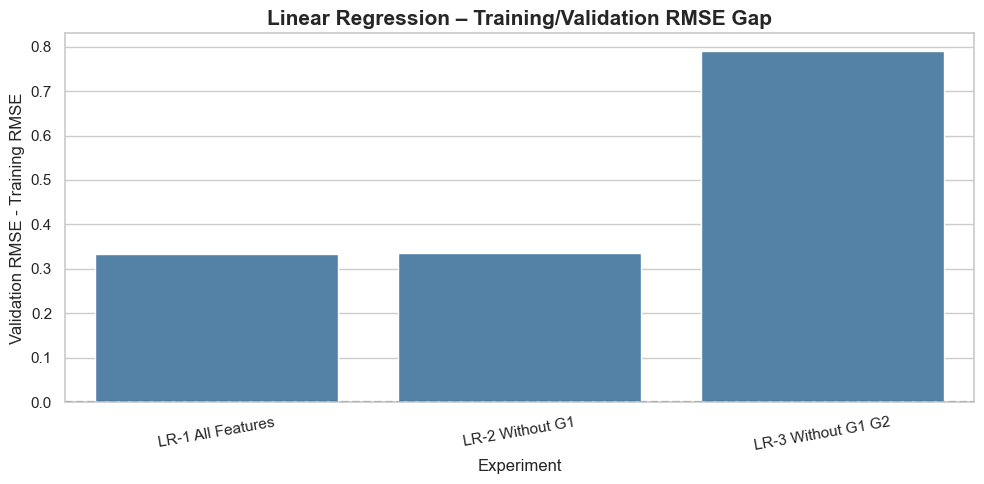

In [31]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=lr_results,
    x="Experiment",
    y="RMSE Gap",
    color="steelblue"
)

plt.axhline(0, color="black", linestyle="--")

plt.title(
    "Linear Regression – Training/Validation RMSE Gap",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Validation RMSE - Training RMSE")
plt.xticks(rotation=10)

plt.tight_layout()
save_plot("06_LR_Overfitting_Gap.png")

Compare with a baseline model

In [32]:
baseline = DummyRegressor(strategy="mean")

baseline_scores = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

baseline_rmse = np.sqrt(
    -baseline_scores["test_MSE"]
).mean()

print(f"Baseline Validation RMSE: {baseline_rmse:.4f}")

lr_results["Better Than Baseline"] = (
    lr_results["Validation RMSE"] < baseline_rmse
)

display(lr_results.round(4))

Baseline Validation RMSE: 4.5635


,Experiment,Features,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train R2,Validation R2,RMSE Gap,Exact Accuracy (%),Within 1 Grade (%),Within 2 Grades (%),Category Accuracy (%),Precision,Recall,F1 Score,Better Than Baseline
0,LR-1 All Features,58,1.1250,1.3724,1.5492,1.8829,0.8855,0.8239,0.3337,30.3797,51.8987,78.7975,80.3797,0.8232,0.8038,0.8026,True
1,LR-2 Without G1,57,1.1361,1.3795,1.5845,1.9211,0.8802,0.8168,0.3366,31.3291,50.6329,77.8481,80.6962,0.8222,0.8070,0.8063,True
2,LR-3 Without G1 G2,56,2.8546,3.4763,3.6714,4.4615,0.3554,-0.0308,0.7902,11.7089,23.1013,37.3418,51.5823,0.4810,0.5158,0.4865,True


Select the best configuration

In [46]:
best_result = final_comparison.iloc[0]

best_name = best_result["Experiment"]
best_features = experiments[best_name]

print("=" * 55)
print("BEST LINEAR REGRESSION CONFIGURATION")
print("=" * 55)

print("Experiment:", best_name)
print("Number of features:", len(best_features))

print("\nREGRESSION METRICS")
print(f"Validation RMSE : {best_result['Validation RMSE']:.4f}")
print(f"Validation MAE  : {best_result['Validation MAE']:.4f}")
print(f"Validation R²   : {best_result['Validation R2']:.4f}")
print(f"RMSE Gap        : {best_result['RMSE Gap']:.4f}")

print("\nGRADE ACCURACY")
print(f"Exact Accuracy  : {best_result['Exact Accuracy (%)']:.2f}%")
print(f"Within ±1 Grade : {best_result['Within 1 Grade (%)']:.2f}%")
print(f"Within ±2 Grades: {best_result['Within 2 Grades (%)']:.2f}%")

print("\nPASS/FAIL CLASSIFICATION")
print(f"Accuracy : {best_result['Accuracy (%)']:.2f}%")
print(f"Precision: {best_result['Precision_Binary']:.4f}")
print(f"Recall   : {best_result['Recall_Binary']:.4f}")
print(f"F1 Score : {best_result['F1 Score_Binary']:.4f}")

print("\nCONFUSION MATRIX VALUES")
print(f"TP: {int(best_result['TP'])}")
print(f"TN: {int(best_result['TN'])}")
print(f"FP: {int(best_result['FP'])}")
print(f"FN: {int(best_result['FN'])}")

BEST LINEAR REGRESSION CONFIGURATION
Experiment: LR-1 All Features
Number of features: 58

REGRESSION METRICS
Validation RMSE : 1.8829
Validation MAE  : 1.3724
Validation R²   : 0.8239
RMSE Gap        : 0.3337

GRADE ACCURACY
Exact Accuracy  : 30.38%
Within ±1 Grade : 51.90%
Within ±2 Grades: 78.80%

PASS/FAIL CLASSIFICATION
Accuracy : 86.08%
Precision: 0.9774
Recall   : 0.8122
F1 Score : 0.8872

CONFUSION MATRIX VALUES
TP: 173
TN: 99
FP: 4
FN: 40
